# Choose a prior for statement preferences

Check how much preference an intercept prior puts on any one ranking
before fitting the model. Compare two intercept priors on the same triplet
design.

## Link the intercept prior to ranking probabilities

For statement $j$, let $b_j$ be the intercept, $a_j>0$ the loading
magnitude, $q_j$ the keying sign and $\theta_{p,t(j)}$ the score of person
$p$ on the statement's trait. [MGPPM](mgppm_workflow.ipynb#model-the-ranking-patterns)
uses statement utility $u_{pj}=q_j a_j\theta_{p,t(j)}-b_j$. The order
$A>B>C$ has weight $\exp(2u_{pA}+u_{pB})$, and its probability is that
weight divided by the sum over the six orders. Large differences in
intercepts can make one order much more likely than the rest.

The two models in this prior predictive comparison use the same design
and reference intercepts. They differ only in the scale of the prior
for free intercepts:

$$
b_j\sim\mathcal N(0,\sigma^2),\qquad
\sigma=2\ \text{(default)}\quad\text{or}\quad\sigma=0.5\ \text{(narrower)}.
$$

In each simulated set of answers, let $n_r$ be the count for order $r$
in block B1 and $n$ the total count. The check uses

$$
T=\max_r(n_r/n).
$$

This is the observed share for the most common order in that simulated
dataset. It is $1/6$ for six equally frequent orders and 1 when everybody
gives the same order.

## Use one design for both priors

Use 80 respondents from the bundled MGPPM simulation. B1 presents three
statements, giving six possible complete orders.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("simulated_mgppm", model="MGPPM", n_persons=80)
example.data.design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,S1,theta1,1
1,B1,2,S2,theta2,1
2,B1,3,S3,theta3,1


## Change one prior

Prepare both models from the same input. In the second model, set the
statement-intercept prior SD to 0.5. Use [`Model.set_priors()`](../reference/generated/pyfcirt.Model.set_priors.md) to assign a PyMC distribution to the intercept prior.

In [2]:
import pymc as pm

default = fc.Model()
default.add_fc(
    example.data.design,
    example.data.responses.frame,
    format="block_long",
    response_format="rank",
    model="MGPPM",
)
default.prepare()
narrower = fc.Model(default.prepared)
narrower.set_priors({"fc.intercept": pm.Normal.dist(mu=0, sigma=0.5)})

## Compare the rankings implied by the priors

Generate 500 prior predictive datasets per model. In each dataset, compute
$T$, the share of responses giving the most frequent order in B1. The order
that attains the maximum can vary across datasets. [`prior_predictive()`](../reference/generated/pyfcirt.prior_predictive.md) generates the replicated responses and [`predictive_view()`](../reference/generated/pyfcirt.predictive_view.md) selects block B1.

In [3]:
import numpy as np
import pandas as pd
import xarray as xr

categories = xr.DataArray(np.arange(6), dims="category")
rows = []
for label, model in [
    ("Default (SD 2)", default),
    ("Narrower (SD 0.5)", narrower),
]:
    prior = model.prior_predictive(draws=500, random_seed=48, store=False)
    view = fc.predictive_view(prior, block="B1")
    response = view.prior_predictive.response
    share = (response == categories).mean("obs").max("category")
    rows.append(share.to_series().rename("share").reset_index().assign(prior=label))

shares = pd.concat(rows, ignore_index=True)

The curves show the fraction of simulated questionnaires with a share at
or below each value. A curve farther right puts more weight on a single
order being common. The dashed line marks the recorded share in B1.
It is 57 of 80 responses (71%), above both priors' 90th percentiles.

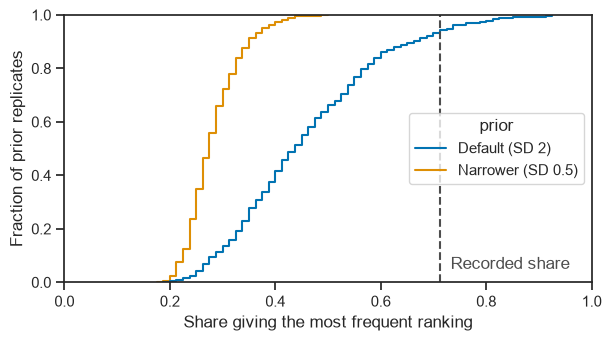

In [4]:
import matplotlib.pyplot as plt

observed = view.observed_data.response.values
observed_share = np.bincount(observed).max() / len(observed)
fig, ax = plt.subplots(figsize=(6, 3.3), layout="constrained")
sns.ecdfplot(shares, x="share", hue="prior", palette="colorblind", ax=ax)
ax.axvline(observed_share, color="0.3", linestyle="--")
ax.text(observed_share + 0.02, 0.05, "Recorded share", color="0.3")
ax.set(
    xlim=(0, 1),
    xlabel="Share giving the most frequent ranking",
    ylabel="Fraction of prior replicates",
)
plt.show()

The median share is 0.44 under the default prior and 0.28 under the
narrower prior. The default prior puts one order at or above about 0.66
of responses in 10% of replicates. A narrower prior reflects a stronger expectation of similar initial appeal.
The recorded concentration is unusual under both priors.

## Set priors on a covariate's intercept and slope

This separate example uses the supplied statement desirability scores
in the empirical FC3 data. Regress the MGPPM discrimination on centered
desirability. The intercept is the expected log discrimination at the
mean desirability. The slope is its change per one rating unit.
The code specifies both priors and builds the model. [`Regression`](../reference/generated/pyfcirt.Regression.md) declares the predictor and priors. [`Model.add_regressions()`](../reference/generated/pyfcirt.Model.add_regressions.md) binds the regression to the loading magnitudes.

In [5]:
fc3 = fc.load_example("hexaco_fc3", model="MGPPM").data
regression = fc.Regression(
    "1 + desirability",
    fc3.statement_features,
    id="statement_id",
    priors={
        "Intercept": pm.Normal.dist(mu=0, sigma=0.5),
        "desirability": pm.Normal.dist(mu=0, sigma=0.25),
    },
)
covariate_model = fc.Model()
covariate_model.add_fc(
    fc3.design,
    fc3.responses.frame,
    format="block_long",
    model="MGPPM",
    response_format="mole",
)
covariate_model.prepare()
covariate_model.add_regressions({("fc", "loading_magnitude"): regression})
covariate_model.build();